# Ejercicio 1 - Modelos CNN para clasificación multietiqueta

## 1. Objetivo

Este notebook implementa modelos de clasificación multietiqueta para
predecir simultáneamente 12 hallazgos en MRI de rodilla.

Se utilizará el dataset 2.5D generado previamente, donde cada estudio
está representado por tres vistas del volumen y cada vista contiene
tres cortes contiguos.

Se evaluarán dos enfoques:

1. CNN 2.5D diseñada desde cero.
2. Modelo con transfer learning utilizando un backbone preentrenado
   en ImageNet.

Las etiquetas débiles con valor `-1` representan abstenciones y serán
ignoradas durante el cálculo de la función de pérdida.

# 2. Imports y reproducibilidad

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader
)

from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Device: cpu


# 3. Localizar nuestros dos archivos

In [2]:
def buscar_archivo(nombre):

    candidatos = list(
        Path("/kaggle/input/datasets").rglob(
            nombre
        )
    )

    if len(candidatos) == 0:
        raise FileNotFoundError(
            f"No se encontró {nombre}"
        )

    print(
        nombre,
        "→",
        candidatos[0]
    )

    return str(
        candidatos[0]
    )


IMAGE_PATH = buscar_archivo(
    "images_2_5d_uint8.npy"
)

METADATA_PATH = buscar_archivo(
    "metadata_2_5d.csv"
)

images_2_5d_uint8.npy → /kaggle/input/datasets/mariomasias/ejercicio-1-dataset-2-5d/images_2_5d_uint8.npy
metadata_2_5d.csv → /kaggle/input/datasets/mariomasias/ejercicio-1-dataset-2-5d/metadata_2_5d.csv


# 4. Cargar dataset

In [3]:
X = np.load(
    IMAGE_PATH,
    mmap_mode="r"
)

metadata = pd.read_csv(
    METADATA_PATH,
    dtype={
        "StudyInstanceUID": str
    }
)

print(
    "Forma imágenes:",
    X.shape
)

print(
    "Tipo:",
    X.dtype
)

print(
    "Metadata:",
    metadata.shape
)

print("\nSplits:")
print(
    metadata["Split"]
    .value_counts()
)

Forma imágenes: (546, 3, 3, 224, 224)
Tipo: uint8
Metadata: (546, 23)

Splits:
Split
train         490
validation     39
test           17
Name: count, dtype: int64


# 5. Definir las 12 etiquetas

In [4]:
LABELS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

NUM_CLASSES = len(LABELS)

print(
    "Número de clases:",
    NUM_CLASSES
)

Número de clases: 12


# 6. Analizamos las etiquetas

In [5]:
train_meta = metadata[
    metadata["Split"] == "train"
].copy()

resumen_labels = []

for label in LABELS:

    valores = train_meta[label]

    positivos = (
        valores == 1
    ).sum()

    negativos = (
        valores == 0
    ).sum()

    abstenciones = (
        valores == -1
    ).sum()

    resueltos = (
        positivos + negativos
    )

    cobertura = (
        resueltos / len(train_meta)
    )

    resumen_labels.append({
        "Label": label,
        "Positivos": positivos,
        "Negativos": negativos,
        "Abstenciones": abstenciones,
        "Cobertura": cobertura
    })

resumen_labels = pd.DataFrame(
    resumen_labels
)

display(
    resumen_labels
)

,Label,Positivos,Negativos,Abstenciones,Cobertura
0,ACL,91,366,33,0.932653
1,MCL,29,399,62,0.873469
2,Medial Meniscus,231,158,101,0.793878
3,Lateral Meniscus,134,269,87,0.822449
4,Medial OA,98,179,213,0.565306
5,Lateral OA,98,197,195,0.602041
6,PF OA,168,215,107,0.781633
7,Effusion,222,204,64,0.869388
8,Synovitis,78,200,212,0.567347
9,Baker's,126,228,136,0.722449


# 7. Dataset de PyTorch

In [6]:
class Knee2_5DDataset(Dataset):

    def __init__(
        self,
        images,
        metadata,
        labels
    ):

        self.images = images
        self.metadata = (
            metadata
            .reset_index(drop=True)
        )

        self.labels = labels

    def __len__(self):

        return len(
            self.metadata
        )

    def __getitem__(
        self,
        idx
    ):

        row = self.metadata.iloc[idx]

        image_index = int(
            row["ImageIndex"]
        )

        x = (
            self.images[
                image_index
            ]
            .astype(np.float32)
            / 255.0
        )

        y = (
            row[self.labels]
            .to_numpy(
                dtype=np.float32
            )
        )

        x = torch.from_numpy(x)

        y = torch.from_numpy(y)

        return x, y

# 8. Crear train / validation / test

In [7]:
train_df = metadata[
    metadata["Split"] == "train"
].copy()

val_df = metadata[
    metadata["Split"] == "validation"
].copy()

test_df = metadata[
    metadata["Split"] == "test"
].copy()


train_dataset = Knee2_5DDataset(
    X,
    train_df,
    LABELS
)

val_dataset = Knee2_5DDataset(
    X,
    val_df,
    LABELS
)

test_dataset = Knee2_5DDataset(
    X,
    test_df,
    LABELS
)


print(
    "Train:",
    len(train_dataset)
)

print(
    "Validation:",
    len(val_dataset)
)

print(
    "Test:",
    len(test_dataset)
)

Train: 490
Validation: 39
Test: 17


# 9. DataLoaders

In [8]:
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

In [9]:
x_batch, y_batch = next(
    iter(train_loader)
)

print(
    "X batch:",
    x_batch.shape
)

print(
    "Y batch:",
    y_batch.shape
)

print(
    "X rango:",
    x_batch.min().item(),
    x_batch.max().item()
)

print(
    "Valores Y:",
    torch.unique(
        y_batch
    )
)

X batch: torch.Size([8, 3, 3, 224, 224])
Y batch: torch.Size([8, 12])
X rango: 0.0 1.0
Valores Y: tensor([-1.,  0.,  1.])


## 10. Manejo del desbalance de clases

El conjunto de entrenamiento presenta diferente prevalencia entre los
12 hallazgos.

Para compensar este desbalance se calcula un peso positivo por clase
utilizando únicamente las etiquetas resueltas:

**pos_weight = negativos / positivos**

Las etiquetas con valor `-1` corresponden a abstenciones y no
participan en este cálculo ni en la función de pérdida.

In [10]:
pos_weights = []

for label in LABELS:

    valores = train_df[label]

    positivos = (valores == 1).sum()
    negativos = (valores == 0).sum()

    peso = negativos / max(positivos, 1)

    pos_weights.append(peso)


pos_weight = torch.tensor(
    pos_weights,
    dtype=torch.float32
)

tabla_pos_weight = pd.DataFrame({
    "Label": LABELS,
    "PosWeight": pos_weights
})

display(tabla_pos_weight)

,Label,PosWeight
0,ACL,4.021978
1,MCL,13.758621
2,Medial Meniscus,0.683983
3,Lateral Meniscus,2.007463
4,Medial OA,1.826531
5,Lateral OA,2.010204
6,PF OA,1.279762
7,Effusion,0.918919
8,Synovitis,2.564103
9,Baker's,1.809524


## 11. Función de pérdida con máscara

Las etiquetas débiles pueden tomar los valores:

- `1`: hallazgo presente.
- `0`: hallazgo ausente.
- `-1`: abstención.

Las etiquetas `-1` no deben interpretarse como negativas. Por ello se
utiliza una función BCE con máscara que calcula la pérdida únicamente
sobre etiquetas resueltas.

In [11]:
def masked_bce_with_logits(
    logits,
    targets,
    pos_weight=None
):

    mask = (
        targets != -1
    ).float()

    safe_targets = (
        targets
        .clamp(0, 1)
    )

    loss = F.binary_cross_entropy_with_logits(
        logits,
        safe_targets,
        reduction="none",
        pos_weight=pos_weight
    )

    loss = loss * mask

    return (
        loss.sum()
        /
        mask.sum().clamp_min(1.0)
    )

In [12]:
logits_prueba = torch.randn(
    y_batch.shape
)

loss_prueba = masked_bce_with_logits(
    logits_prueba,
    y_batch,
    pos_weight=pos_weight
)

print(
    "Loss de prueba:",
    loss_prueba.item()
)

Loss de prueba: 0.8989017009735107


## 12. CNN 2.5D diseñada desde cero

Cada una de las tres vistas 2.5D se procesa mediante la misma CNN 2D.
Los tres cortes contiguos de cada vista se utilizan como los tres
canales de entrada.

Las características obtenidas para las tres vistas se agregan mediante
promedio y posteriormente se utilizan para producir las 12 salidas
multietiqueta.

In [13]:
class CNN2_5D(nn.Module):

    def __init__(
        self,
        num_classes=12
    ):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                3,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                128,
                256,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d(
                (1, 1)
            )
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                256,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(
                128,
                num_classes
            )
        )


    def forward(
        self,
        x
    ):

        # x:
        # [B, 3 vistas, 3 canales, H, W]

        batch_size = x.size(0)
        num_views = x.size(1)

        x = x.view(
            batch_size * num_views,
            3,
            x.size(-2),
            x.size(-1)
        )

        features = self.features(x)

        features = features.view(
            batch_size,
            num_views,
            256,
            1,
            1
        )

        # agregación de las 3 vistas
        features = features.mean(
            dim=1
        )

        logits = self.classifier(
            features
        )

        return logits

In [14]:
model = CNN2_5D(
    num_classes=NUM_CLASSES
)

with torch.no_grad():

    logits = model(
        x_batch
    )

print(
    "Entrada:",
    x_batch.shape
)

print(
    "Salida:",
    logits.shape
)

Entrada: torch.Size([8, 3, 3, 224, 224])
Salida: torch.Size([8, 12])


## 13. Entrenamiento de la CNN 2.5D

La CNN diseñada desde cero se entrena utilizando las 490 muestras
con etiquetas débiles.

Las etiquetas con valor `-1` se ignoran mediante la función de pérdida
con máscara.

La validación se realiza exclusivamente sobre los 39 estudios GOLD DEV.
El conjunto GOLD HOLDOUT permanece reservado para la evaluación final.

In [15]:
model = CNN2_5D(
    num_classes=NUM_CLASSES
).to(device)

pos_weight_gpu = pos_weight.to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print(
    "Parámetros entrenables:",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
)

Parámetros entrenables: 423820


In [16]:
def entrenar_una_epoca(
    model,
    loader,
    optimizer,
    device,
    pos_weight
):

    model.train()

    loss_total = 0.0
    n_batches = 0

    for x, y in loader:

        x = x.to(
            device,
            non_blocking=True
        )

        y = y.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        logits = model(x)

        loss = masked_bce_with_logits(
            logits,
            y,
            pos_weight=pos_weight
        )

        loss.backward()

        optimizer.step()

        loss_total += loss.item()
        n_batches += 1

    return (
        loss_total /
        max(n_batches, 1)
    )

In [17]:
EJECUTAR_EPOCA_PILOTO = False

if EJECUTAR_EPOCA_PILOTO:

    loss_train = entrenar_una_epoca(
        model,
        train_loader,
        optimizer,
        device,
        pos_weight_gpu
    )

    print(
        "Loss entrenamiento - época 1:",
        loss_train
    )

else:

    print(
        "Época piloto omitida."
    )

Época piloto omitida.


## 14. Evaluación durante el entrenamiento

El rendimiento se monitoriza sobre los 39 estudios GOLD DEV mediante
AUC-ROC por etiqueta y AUC macro.

Debido al reducido tamaño del conjunto de validación, una etiqueta
puede presentar una sola clase en alguna partición. En ese caso su AUC
no puede calcularse y se excluye únicamente del promedio macro.

In [18]:
def evaluar_modelo(
    model,
    loader,
    device,
    labels
):

    model.eval()

    targets_all = []
    probs_all = []

    with torch.no_grad():

        for x, y in loader:

            x = x.to(
                device,
                non_blocking=True
            )

            logits = model(x)

            probs = torch.sigmoid(
                logits
            )

            targets_all.append(
                y.numpy()
            )

            probs_all.append(
                probs.cpu().numpy()
            )

    y_true = np.concatenate(
        targets_all,
        axis=0
    )

    y_prob = np.concatenate(
        probs_all,
        axis=0
    )

    aucs = {}

    for i, label in enumerate(labels):

        y_label = y_true[:, i]
        p_label = y_prob[:, i]

        # AUC necesita positivos y negativos
        if len(np.unique(y_label)) < 2:

            aucs[label] = np.nan

        else:

            aucs[label] = roc_auc_score(
                y_label,
                p_label
            )

    auc_macro = np.nanmean(
        list(aucs.values())
    )

    return auc_macro, aucs

In [19]:
# Semilla antes de crear nuevamente el modelo
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model = CNN2_5D(
    num_classes=NUM_CLASSES
).to(device)

pos_weight_gpu = (
    pos_weight.to(device)
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

In [20]:
auc_inicial, aucs_iniciales = (
    evaluar_modelo(
        model,
        val_loader,
        device,
        LABELS
    )
)

print(
    "AUC macro antes de entrenar:",
    round(auc_inicial, 4)
)

display(
    pd.DataFrame({
        "Label": LABELS,
        "AUC_inicial": [
            aucs_iniciales[label]
            for label in LABELS
        ]
    })
)

AUC macro antes de entrenar: 0.5183


,Label,AUC_inicial
0,ACL,0.336957
1,MCL,0.545455
2,Medial Meniscus,0.684492
3,Lateral Meniscus,0.548913
4,Medial OA,0.286207
5,Lateral OA,0.758065
6,PF OA,0.437870
7,Effusion,0.449074
8,Synovitis,0.529101
9,Baker's,0.612903


### Entrenamiento formal

In [21]:
EPOCHS = 15
PATIENCE = 4

# False = cargar resultados ya entrenados
# True  = volver a entrenar la CNN desde cero
ENTRENAR_CNN_DESDE_CERO = False
if ENTRENAR_CNN_DESDE_CERO:

    best_auc = -np.inf
    best_epoch = 0
    epochs_sin_mejora = 0
    historial = []

    BEST_MODEL_PATH = (
        "/kaggle/working/"
        "best_cnn_2_5d.pth"
    )

else:

    from pathlib import Path

    BEST_MODEL_PATH = str(
        list(
            Path("/kaggle/input").rglob(
                "best_cnn_2_5d.pth"
            )
        )[0]
    )

    HISTORIAL_PATH = str(
        list(
            Path("/kaggle/input").rglob(
                "historial_cnn_2_5d.csv"
            )
        )[0]
    )

    METRICAS_CNN_PATH = str(
        list(
            Path("/kaggle/input").rglob(
                "metricas_dev_cnn_2_5d.csv"
            )
        )[0]
    )

    historial_df = pd.read_csv(
        HISTORIAL_PATH
    )

    mejor_idx = (
        historial_df["val_auc_macro"]
        .idxmax()
    )

    best_epoch = int(
        historial_df.loc[
            mejor_idx,
            "epoch"
        ]
    )

    best_auc = float(
        historial_df.loc[
            mejor_idx,
            "val_auc_macro"
        ]
    )

    print(
        "Entrenamiento CNN omitido."
    )

    print(
        "Checkpoint:",
        BEST_MODEL_PATH
    )

    print(
        "Mejor época:",
        best_epoch
    )

    print(
        "Mejor AUC:",
        round(best_auc, 4)
    )

Entrenamiento CNN omitido.
Checkpoint: /kaggle/input/datasets/mariomasias/ejercicio-1-modelo1-cnn-resultados/best_cnn_2_5d.pth
Mejor época: 4
Mejor AUC: 0.6614


In [22]:

if ENTRENAR_CNN_DESDE_CERO:
    
    for epoch in range(
        1,
        EPOCHS + 1
    ):
    
        loss_train = entrenar_una_epoca(
            model,
            train_loader,
            optimizer,
            device,
            pos_weight_gpu
        )
    
        val_auc, val_aucs = evaluar_modelo(
            model,
            val_loader,
            device,
            LABELS
        )
    
        historial.append({
            "epoch": epoch,
            "train_loss": loss_train,
            "val_auc_macro": val_auc
        })
    
        print(
            f"Epoch {epoch:02d} | "
            f"Loss: {loss_train:.4f} | "
            f"Val AUC: {val_auc:.4f}"
        )
    
        # --------------------------
        # Guardar mejor modelo
        # --------------------------
    
        if val_auc > best_auc:
    
            best_auc = val_auc
            best_epoch = epoch
            epochs_sin_mejora = 0
    
            torch.save(
                model.state_dict(),
                BEST_MODEL_PATH
            )
    
            print(
                "   ✓ Mejor modelo guardado"
            )
    
        else:
    
            epochs_sin_mejora += 1
    
        # --------------------------
        # Early stopping
        # --------------------------
    
        if epochs_sin_mejora >= PATIENCE:
    
            print(
                "\nEarly stopping."
            )
    
            break
else:
    print("Entrenamiento CNN omitido. Se utilizará el checkpoint guardado.")

Entrenamiento CNN omitido. Se utilizará el checkpoint guardado.


In [23]:
print(
    "\nMejor época:",
    best_epoch
)

print(
    "Mejor AUC macro validation:",
    round(best_auc, 4)
)


Mejor época: 4
Mejor AUC macro validation: 0.6614


In [24]:
if ENTRENAR_CNN_DESDE_CERO:

    historial_df = pd.DataFrame(
        historial
    )

else:

    historial_df = pd.read_csv(
        HISTORIAL_PATH
    )

display(historial_df)

,epoch,train_loss,val_auc_macro
0,1,0.896563,0.611918
1,2,0.853575,0.631410
2,3,0.855296,0.651586
3,4,0.838117,0.661418
4,5,0.807364,0.656802
5,6,0.818136,0.599641
6,7,0.785797,0.645119
7,8,0.805442,0.651669


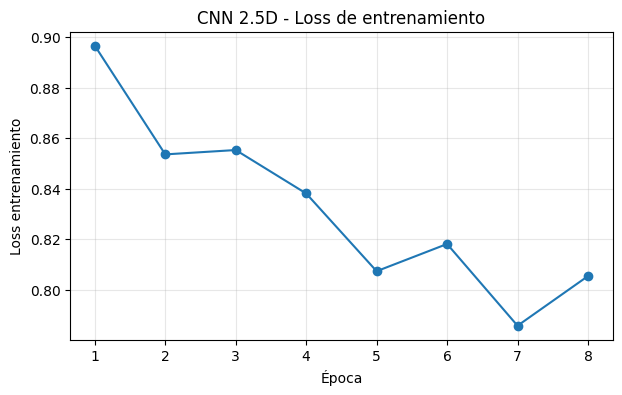

In [25]:
plt.figure(figsize=(7, 4))

plt.plot(
    historial_df["epoch"],
    historial_df["train_loss"],
    marker="o"
)

plt.xlabel("Época")
plt.ylabel("Loss entrenamiento")
plt.title("CNN 2.5D - Loss de entrenamiento")
plt.grid(alpha=0.3)

plt.show()

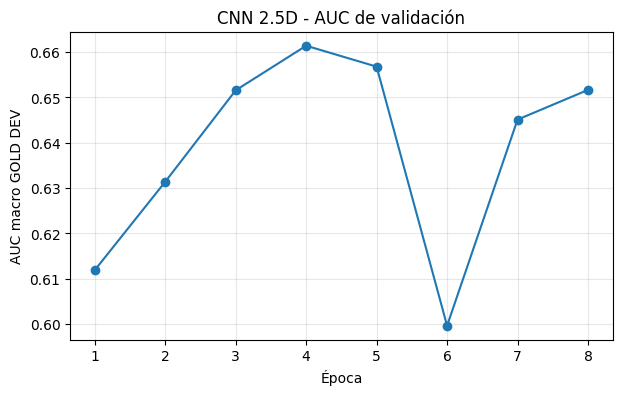

In [26]:
plt.figure(figsize=(7, 4))

plt.plot(
    historial_df["epoch"],
    historial_df["val_auc_macro"],
    marker="o"
)

plt.xlabel("Época")
plt.ylabel("AUC macro GOLD DEV")
plt.title("CNN 2.5D - AUC de validación")
plt.grid(alpha=0.3)

plt.show()

## 15. Evaluación del mejor modelo CNN 2.5D

Se recupera el checkpoint correspondiente a la época con mayor
AUC macro sobre GOLD DEV.

El conjunto GOLD HOLDOUT permanece sin utilizar.

In [27]:
model_best = CNN2_5D(
    num_classes=NUM_CLASSES
).to(device)

model_best.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

model_best.eval()

print(
    "Mejor modelo cargado:",
    BEST_MODEL_PATH
)

print(
    "Mejor época:",
    best_epoch
)

print(
    "AUC macro DEV:",
    round(best_auc, 4)
)

Mejor modelo cargado: /kaggle/input/datasets/mariomasias/ejercicio-1-modelo1-cnn-resultados/best_cnn_2_5d.pth
Mejor época: 4
AUC macro DEV: 0.6614


In [28]:
auc_macro_best, aucs_best = evaluar_modelo(
    model_best,
    val_loader,
    device,
    LABELS
)

tabla_auc_best = pd.DataFrame({
    "Patologia": LABELS,
    "AUC_DEV": [
        aucs_best[label]
        for label in LABELS
    ]
})

display(
    tabla_auc_best.sort_values(
        "AUC_DEV",
        ascending=False
    )
)

print(
    "AUC macro GOLD DEV:",
    round(auc_macro_best, 4)
)

,Patologia,AUC_DEV
7,Effusion,0.882716
5,Lateral OA,0.758065
3,Lateral Meniscus,0.709239
8,Synovitis,0.690476
11,Fracture,0.688272
2,Medial Meniscus,0.681818
6,PF OA,0.671598
0,ACL,0.644022
9,Baker's,0.612903
4,Medial OA,0.582759


AUC macro GOLD DEV: 0.6614


In [29]:
def obtener_predicciones(
    model,
    loader,
    device
):

    model.eval()

    y_true_all = []
    y_prob_all = []

    with torch.no_grad():

        for x, y in loader:

            x = x.to(
                device,
                non_blocking=True
            )

            logits = model(x)

            probs = torch.sigmoid(
                logits
            )

            y_true_all.append(
                y.numpy()
            )

            y_prob_all.append(
                probs.cpu().numpy()
            )

    return (
        np.concatenate(
            y_true_all,
            axis=0
        ),
        np.concatenate(
            y_prob_all,
            axis=0
        )
    )

In [30]:
y_val, prob_val = obtener_predicciones(
    model_best,
    val_loader,
    device
)

THRESHOLD = 0.5

pred_val = (
    prob_val >= THRESHOLD
).astype(int)

metricas_dev = []

for i, label in enumerate(LABELS):

    metricas_dev.append({
        "Patologia": label,

        "AUC": roc_auc_score(
            y_val[:, i],
            prob_val[:, i]
        ),

        "Precision": precision_score(
            y_val[:, i],
            pred_val[:, i],
            zero_division=0
        ),

        "Recall": recall_score(
            y_val[:, i],
            pred_val[:, i],
            zero_division=0
        ),

        "F1": f1_score(
            y_val[:, i],
            pred_val[:, i],
            zero_division=0
        )
    })


metricas_dev = pd.DataFrame(
    metricas_dev
)

display(metricas_dev)

,Patologia,AUC,Precision,Recall,F1
0,ACL,0.644022,0.437500,0.875000,0.583333
1,MCL,0.515152,0.166667,0.833333,0.277778
2,Medial Meniscus,0.681818,0.459459,1.000000,0.629630
3,Lateral Meniscus,0.709239,0.441176,0.937500,0.600000
4,Medial OA,0.582759,0.285714,0.600000,0.387097
5,Lateral OA,0.758065,0.333333,0.875000,0.482759
6,PF OA,0.671598,0.444444,0.615385,0.516129
7,Effusion,0.882716,0.787879,0.962963,0.866667
8,Synovitis,0.690476,0.600000,1.000000,0.750000
9,Baker's,0.612903,0.233333,0.875000,0.368421


In [31]:
print(
    "AUC macro:",
    metricas_dev["AUC"].mean()
)

print(
    "Precision macro:",
    metricas_dev["Precision"].mean()
)

print(
    "Recall macro:",
    metricas_dev["Recall"].mean()
)

print(
    "F1 macro:",
    metricas_dev["F1"].mean()
)

AUC macro: 0.6614182005911106
Precision macro: 0.41063350162614864
Recall macro: 0.8416518281101615
F1 macro: 0.5380327360816427


In [32]:
historial_df.to_csv(
    "/kaggle/working/historial_cnn_2_5d.csv",
    index=False
)

metricas_dev.to_csv(
    "/kaggle/working/metricas_dev_cnn_2_5d.csv",
    index=False
)

## 16. Modelo 2: Transfer Learning con EfficientNet-B0

Como segunda arquitectura se utiliza EfficientNet-B0 preentrenada en ImageNet.

Cada estudio mantiene la representación 2.5D utilizada en el modelo anterior:
tres vistas de la rodilla, donde cada vista está formada por tres cortes contiguos tratados como canales de entrada.

La misma EfficientNet procesa de manera compartida las tres vistas. Los vectores de características obtenidos se promedian y se utilizan para predecir los 12 hallazgos mediante una capa lineal.

Durante el entrenamiento se trabajará con logits y BCEWithLogitsLoss. La función sigmoide se aplicará durante la evaluación para obtener probabilidades independientes por hallazgo.

### Importar EfficientNet

In [33]:
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

In [34]:
class EfficientNet2_5D(nn.Module):

    def __init__(
        self,
        num_classes=12,
        dropout=0.3,
        usar_imagenet=True
    ):

        super().__init__()

        if usar_imagenet:
            weights = (
                EfficientNet_B0_Weights
                .IMAGENET1K_V1
            )
        else:
            weights = None

        self.backbone = efficientnet_b0(
            weights=weights
        )

        self.feature_dim = (
            self.backbone
            .classifier[1]
            .in_features
        )

        # Eliminamos clasificador original ImageNet
        self.backbone.classifier = nn.Identity()

        # Clasificador multietiqueta
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(
                self.feature_dim,
                num_classes
            )
        )

        # Normalización usada por ImageNet
        mean = torch.tensor(
            [0.485, 0.456, 0.406],
            dtype=torch.float32
        ).view(1, 1, 3, 1, 1)

        std = torch.tensor(
            [0.229, 0.224, 0.225],
            dtype=torch.float32
        ).view(1, 1, 3, 1, 1)

        self.register_buffer(
            "imagenet_mean",
            mean
        )

        self.register_buffer(
            "imagenet_std",
            std
        )


    def forward(self, x):

        # x:
        # [batch, views, channels, H, W]
        #
        # Ejemplo:
        # [8, 3, 3, 224, 224]

        B, V, C, H, W = x.shape

        # Normalización ImageNet
        x = (
            x - self.imagenet_mean
        ) / self.imagenet_std

        # Cada vista pasa independientemente
        # por la misma EfficientNet
        x = x.reshape(
            B * V,
            C,
            H,
            W
        )

        features = self.backbone(x)

        # [B*V, feature_dim]
        features = features.reshape(
            B,
            V,
            self.feature_dim
        )

        # Fusionamos las tres vistas
        features = features.mean(
            dim=1
        )

        # [B, 12]
        logits = self.classifier(
            features
        )

        return logits

### Crear Modelo

In [35]:
ENTRENAR_EFFICIENTNET = False

model_effnet = EfficientNet2_5D(
    num_classes=NUM_CLASSES,
    usar_imagenet=ENTRENAR_EFFICIENTNET
).to(device)

print(model_effnet)

EfficientNet2_5D(
  (backbone): EfficientNet(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): Sequential(
        (0): MBConv(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
              (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              (2): SiLU(inplace=True)
            )
            (1): SqueezeExcitation(
              (avgpool): AdaptiveAvgPool2d(output_size=1)
              (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
              (activation): SiLU(inplace=True)
              (s

### Contar Parámetros

In [36]:
total_params = sum(
    p.numel()
    for p in model_effnet.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_effnet.parameters()
    if p.requires_grad
)

print(
    f"Parámetros totales: "
    f"{total_params:,}"
)

print(
    f"Parámetros entrenables: "
    f"{trainable_params:,}"
)

Parámetros totales: 4,022,920
Parámetros entrenables: 4,022,920


### Probamos el forward

In [37]:
if ENTRENAR_EFFICIENTNET:

    X_test, Y_test = next(
        iter(val_loader)
    )

    X_test = X_test[:1].to(device)

    model_effnet.eval()

    with torch.no_grad():

        logits_test = model_effnet(
            X_test
        )

    print(
        "Entrada:",
        X_test.shape
    )

    print(
        "Salida:",
        logits_test.shape
    )

    print(
        "Logits:",
        logits_test
    )

    print(
        "Probabilidades:",
        torch.sigmoid(
            logits_test
        )
    )

else:

    print(
        "Prueba inicial de EfficientNet omitida."
    )

Prueba inicial de EfficientNet omitida.


### Configuración del fine-tuning

Se realiza fine-tuning de todos los parámetros de EfficientNet-B0.

Para preservar el conocimiento adquirido durante el preentrenamiento en ImageNet,
se utiliza una tasa de aprendizaje menor para el backbone y una tasa mayor para
el nuevo clasificador multietiqueta.

Se mantiene la misma función de pérdida utilizada en la CNN desde cero
(masked BCE con ponderación por desbalance), permitiendo una comparación
más justa entre ambas arquitecturas.

In [38]:
LR_BACKBONE = 1e-4
LR_CLASSIFIER = 5e-4
WEIGHT_DECAY = 1e-4

optimizer_effnet = torch.optim.AdamW(
    [
        {
            "params": model_effnet.backbone.parameters(),
            "lr": LR_BACKBONE
        },
        {
            "params": model_effnet.classifier.parameters(),
            "lr": LR_CLASSIFIER
        }
    ],
    weight_decay=WEIGHT_DECAY
)

print(
    "LR backbone:",
    LR_BACKBONE
)

print(
    "LR classifier:",
    LR_CLASSIFIER
)

LR backbone: 0.0001
LR classifier: 0.0005


In [39]:
if ENTRENAR_EFFICIENTNET:

    model_effnet.train()

    X_batch, Y_batch = next(
        iter(train_loader)
    )

    X_batch = X_batch[:2].to(device)
    Y_batch = Y_batch[:2].to(device)

    logits = model_effnet(
        X_batch
    )

    loss_test = masked_bce_with_logits(
        logits,
        Y_batch,
        pos_weight_gpu
    )

    print(
        "Shape logits:",
        logits.shape
    )

    print(
        "Loss prueba:",
        loss_test.item()
    )

else:

    print(
        "Prueba de loss EfficientNet omitida."
    )

Prueba de loss EfficientNet omitida.


### Entrenamiento formal de EfficientNet-B0

El modelo se entrena utilizando las etiquetas débiles del conjunto de entrenamiento y se evalúa
después de cada época sobre el conjunto GOLD DEV.

Se utiliza early stopping basado en el AUC-ROC macro para evitar sobreajuste.
El mejor checkpoint se guarda según el desempeño obtenido en validación.

In [40]:
from pathlib import Path
EPOCHS_EFFNET = 15
PATIENCE_EFFNET = 4
# False = cargar EfficientNet ya entrenada
# True  = volver a entrenar desde ImageNet

best_auc_effnet = -np.inf
best_epoch_effnet = 0
epochs_sin_mejora_effnet = 0

historial_effnet = []

if ENTRENAR_EFFICIENTNET:

    BEST_EFFNET_PATH = (
        "/kaggle/working/"
        "best_efficientnet_2_5d.pth"
    )

    historial_effnet = []

else:

    BEST_EFFNET_PATH = str(
        list(
            Path("/kaggle/input").rglob(
                "best_efficientnet_2_5d.pth"
            )
        )[0]
    )

    HISTORIAL_EFFNET_PATH = str(
        list(
            Path("/kaggle/input").rglob(
                "historial_efficientnet_2_5d.csv"
            )
        )[0]
    )

    METRICAS_EFFNET_PATH = str(
        list(
            Path("/kaggle/input").rglob(
                "metricas_dev_efficientnet_2_5d.csv"
            )
        )[0]
    )

    historial_effnet_df = pd.read_csv(
        HISTORIAL_EFFNET_PATH
    )

    historial_effnet = (
        historial_effnet_df
        .to_dict("records")
    )
    
    mejor_idx = (
        historial_effnet_df[
            "val_auc_macro"
        ].idxmax()
    )

    best_epoch_effnet = int(
        historial_effnet_df.loc[
            mejor_idx,
            "epoch"
        ]
    )

    best_auc_effnet = float(
        historial_effnet_df.loc[
            mejor_idx,
            "val_auc_macro"
        ]
    )

    print(
        "Entrenamiento EfficientNet omitido."
    )

    print(
        "Mejor época:",
        best_epoch_effnet
    )

    print(
        "Mejor AUC:",
        round(best_auc_effnet, 4)
    )

Entrenamiento EfficientNet omitido.
Mejor época: 16
Mejor AUC: 0.7665


In [41]:


if ENTRENAR_EFFICIENTNET:

    for epoch in range(
        1,
        EPOCHS_EFFNET + 1
    ):

        loss_train = entrenar_una_epoca(
            model_effnet,
            train_loader,
            optimizer_effnet,
            device,
            pos_weight_gpu
        )

        val_auc, val_aucs = evaluar_modelo(
            model_effnet,
            val_loader,
            device,
            LABELS
        )

        historial_effnet.append({
            "epoch": epoch,
            "train_loss": loss_train,
            "val_auc_macro": val_auc
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Loss: {loss_train:.4f} | "
            f"Val AUC: {val_auc:.4f}"
        )

        if val_auc > best_auc_effnet:

            best_auc_effnet = val_auc
            best_epoch_effnet = epoch
            epochs_sin_mejora_effnet = 0

            torch.save(
                model_effnet.state_dict(),
                BEST_EFFNET_PATH
            )

            print(
                "   ✓ Mejor EfficientNet guardada"
            )

        else:
            epochs_sin_mejora_effnet += 1

        if (
            epochs_sin_mejora_effnet
            >= PATIENCE_EFFNET
        ):
            print("\nEarly stopping.")
            break

else:

    print(
        "Entrenamiento EfficientNet omitido. "
        "Se utilizará el checkpoint guardado."
    )

Entrenamiento EfficientNet omitido. Se utilizará el checkpoint guardado.


In [42]:
print(
    "Mejor época EfficientNet:",
    best_epoch_effnet
)

print(
    "Mejor AUC DEV:",
    round(
        best_auc_effnet,
        4
    )
)

Mejor época EfficientNet: 16
Mejor AUC DEV: 0.7665


In [43]:
historial_effnet_df = pd.DataFrame(
    historial_effnet
)

historial_effnet_df.to_csv(
    "/kaggle/working/"
    "historial_efficientnet_2_5d.csv",
    index=False
)

display(
    historial_effnet_df
)

,epoch,train_loss,val_auc_macro
0,1,0.869426,0.647073
1,2,0.683225,0.673783
2,3,0.522551,0.706188
3,4,0.446700,0.720219
4,5,0.400630,0.730904
5,6,0.331335,0.733643
6,7,0.330715,0.730569
7,8,0.286649,0.735542
8,9,0.253524,0.739134
9,10,0.216610,0.739159


In [44]:
# Continuación del entrenamiento porque
# la mejor validación ocurrió en la época 15
if ENTRENAR_EFFICIENTNET:
    EPOCH_FIN_EFFNET = 20
    
    for epoch in range(
        EPOCHS_EFFNET + 1,
        EPOCH_FIN_EFFNET + 1
    ):
    
        loss_train = entrenar_una_epoca(
            model_effnet,
            train_loader,
            optimizer_effnet,
            device,
            pos_weight_gpu
        )
    
        val_auc, val_aucs = evaluar_modelo(
            model_effnet,
            val_loader,
            device,
            LABELS
        )
    
        historial_effnet.append({
            "epoch": epoch,
            "train_loss": loss_train,
            "val_auc_macro": val_auc
        })
    
        print(
            f"Epoch {epoch:02d} | "
            f"Loss: {loss_train:.4f} | "
            f"Val AUC: {val_auc:.4f}"
        )
    
        if val_auc > best_auc_effnet:
    
            best_auc_effnet = val_auc
            best_epoch_effnet = epoch
            epochs_sin_mejora_effnet = 0
    
            torch.save(
                model_effnet.state_dict(),
                BEST_EFFNET_PATH
            )
    
            print(
                "   ✓ Mejor EfficientNet guardada"
            )
    
        else:
    
            epochs_sin_mejora_effnet += 1
    
        if (
            epochs_sin_mejora_effnet
            >= PATIENCE_EFFNET
        ):
    
            print(
                "\nEarly stopping."
            )
    
            break

In [45]:
historial_effnet_df = pd.DataFrame(
    historial_effnet
)

historial_effnet_df.to_csv(
    "/kaggle/working/"
    "historial_efficientnet_2_5d.csv",
    index=False
)

print(
    "Mejor época EfficientNet:",
    best_epoch_effnet
)

print(
    "Mejor AUC DEV:",
    round(
        best_auc_effnet,
        4
    )
)

display(
    historial_effnet_df
)

Mejor época EfficientNet: 16
Mejor AUC DEV: 0.7665


,epoch,train_loss,val_auc_macro
0,1,0.869426,0.647073
1,2,0.683225,0.673783
2,3,0.522551,0.706188
3,4,0.446700,0.720219
4,5,0.400630,0.730904
5,6,0.331335,0.733643
6,7,0.330715,0.730569
7,8,0.286649,0.735542
8,9,0.253524,0.739134
9,10,0.216610,0.739159


EfficientNet-B0 alcanzó su mejor desempeño en la época 16, con un AUC-ROC macro de 0.7665. A partir de dicha época, la pérdida de entrenamiento continuó disminuyendo mientras el AUC de validación se deterioró, indicando el inicio de sobreajuste. El entrenamiento se detuvo mediante early stopping tras cuatro épocas consecutivas sin mejora.

# 1. Cargar la mejor EfficientNet

In [46]:
model_effnet_best = EfficientNet2_5D(
    num_classes=NUM_CLASSES,
    usar_imagenet=False
).to(device)

model_effnet_best.load_state_dict(
    torch.load(
        BEST_EFFNET_PATH,
        map_location=device
    )
)

model_effnet_best.eval()

print(
    "Mejor EfficientNet cargada correctamente."
)

Mejor EfficientNet cargada correctamente.


# 2. Obtener predicciones sobre GOLD DEV

In [47]:
y_true_effnet = []
y_prob_effnet = []

model_effnet_best.eval()

with torch.no_grad():

    for X, y in val_loader:

        X = X.to(device)

        logits = model_effnet_best(X)

        probs = torch.sigmoid(
            logits
        )

        y_true_effnet.append(
            y.cpu().numpy()
        )

        y_prob_effnet.append(
            probs.cpu().numpy()
        )

y_true_effnet = np.concatenate(
    y_true_effnet,
    axis=0
)

y_prob_effnet = np.concatenate(
    y_prob_effnet,
    axis=0
)

print(
    "y_true:",
    y_true_effnet.shape
)

print(
    "y_prob:",
    y_prob_effnet.shape
)

y_true: (39, 12)
y_prob: (39, 12)


# 3. Calcular las métricas por etiqueta

In [48]:
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

THRESHOLD = 0.5

resultados_effnet = []

for i, label in enumerate(LABELS):

    y_true_label = y_true_effnet[:, i]
    y_prob_label = y_prob_effnet[:, i]

    y_pred_label = (
        y_prob_label >= THRESHOLD
    ).astype(int)

    auc = roc_auc_score(
        y_true_label,
        y_prob_label
    )

    precision = precision_score(
        y_true_label,
        y_pred_label,
        zero_division=0
    )

    recall = recall_score(
        y_true_label,
        y_pred_label,
        zero_division=0
    )

    f1 = f1_score(
        y_true_label,
        y_pred_label,
        zero_division=0
    )

    resultados_effnet.append({
        "Label": label,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

metricas_effnet_df = pd.DataFrame(
    resultados_effnet
)

display(metricas_effnet_df)

,Label,AUC,Precision,Recall,F1
0,ACL,0.747283,0.523810,0.687500,0.594595
1,MCL,0.646465,0.250000,0.500000,0.333333
2,Medial Meniscus,0.767380,0.518519,0.823529,0.636364
3,Lateral Meniscus,0.771739,0.625000,0.937500,0.750000
4,Medial OA,0.837931,0.470588,0.800000,0.592593
5,Lateral OA,0.830645,0.454545,0.625000,0.526316
6,PF OA,0.840237,0.666667,0.769231,0.714286
7,Effusion,0.864198,0.866667,0.962963,0.912281
8,Synovitis,0.748677,0.652174,0.833333,0.731707
9,Baker's,0.754032,0.304348,0.875000,0.451613


# 4. Métricas macro

In [49]:
print(
    "AUC macro:",
    metricas_effnet_df["AUC"].mean()
)

print(
    "Precision macro:",
    metricas_effnet_df["Precision"].mean()
)

print(
    "Recall macro:",
    metricas_effnet_df["Recall"].mean()
)

print(
    "F1 macro:",
    metricas_effnet_df["F1"].mean()
)

AUC macro: 0.7664927651273789
Precision macro: 0.5113294306889788
Recall macro: 0.7772397491760236
F1 macro: 0.6077185155343406


# 5. Guardar Resultado

In [50]:
metricas_effnet_df.to_csv(
    "/kaggle/working/"
    "metricas_dev_efficientnet_2_5d.csv",
    index=False
)

historial_effnet_df.to_csv(
    "/kaggle/working/"
    "historial_efficientnet_2_5d.csv",
    index=False
)

print(
    "Resultados EfficientNet guardados."
)

Resultados EfficientNet guardados.


## 17. Comparación CNN 2.5D vs EfficientNet-B0



Se comparan las dos arquitecturas entrenadas bajo el mismo esquema de datos:

- CNN 2.5D diseñada desde cero.
- EfficientNet-B0 preentrenada en ImageNet y posteriormente ajustada mediante fine-tuning.

Ambos modelos fueron entrenados con los 490 estudios con etiquetas débiles y seleccionados
utilizando únicamente los 39 estudios GOLD DEV.

La comparación principal utiliza AUC-ROC macro, complementada con precisión, recall y F1
a un umbral fijo de 0.5.

### 1. Cargar las métricas de ambos modelos

In [51]:
metricas_cnn_comp = pd.read_csv(
    METRICAS_CNN_PATH
)

metricas_effnet_comp = pd.read_csv(
    METRICAS_EFFNET_PATH
)

print("CNN:")
display(metricas_cnn_comp)

print("EfficientNet:")
display(metricas_effnet_comp)

CNN:


,Patologia,AUC,Precision,Recall,F1
0,ACL,0.644022,0.437500,0.875000,0.583333
1,MCL,0.515152,0.166667,0.833333,0.277778
2,Medial Meniscus,0.681818,0.459459,1.000000,0.629630
3,Lateral Meniscus,0.709239,0.441176,0.937500,0.600000
4,Medial OA,0.582759,0.285714,0.600000,0.387097
5,Lateral OA,0.758065,0.333333,0.875000,0.482759
6,PF OA,0.671598,0.444444,0.615385,0.516129
7,Effusion,0.882716,0.787879,0.962963,0.866667
8,Synovitis,0.690476,0.600000,1.000000,0.750000
9,Baker's,0.612903,0.233333,0.875000,0.368421


EfficientNet:


,Label,AUC,Precision,Recall,F1
0,ACL,0.747283,0.523810,0.687500,0.594595
1,MCL,0.646465,0.250000,0.500000,0.333333
2,Medial Meniscus,0.767380,0.518519,0.823529,0.636364
3,Lateral Meniscus,0.771739,0.625000,0.937500,0.750000
4,Medial OA,0.837931,0.470588,0.800000,0.592593
5,Lateral OA,0.830645,0.454545,0.625000,0.526316
6,PF OA,0.840237,0.666667,0.769231,0.714286
7,Effusion,0.864198,0.866667,0.962963,0.912281
8,Synovitis,0.748677,0.652174,0.833333,0.731707
9,Baker's,0.754032,0.304348,0.875000,0.451613


### 2. Comparación macro

In [52]:
resumen_modelos = pd.DataFrame({
    "Modelo": [
        "CNN 2.5D desde cero",
        "EfficientNet-B0 2.5D"
    ],
    "AUC_macro": [
        metricas_cnn_comp["AUC"].mean(),
        metricas_effnet_comp["AUC"].mean()
    ],
    "Precision_macro": [
        metricas_cnn_comp["Precision"].mean(),
        metricas_effnet_comp["Precision"].mean()
    ],
    "Recall_macro": [
        metricas_cnn_comp["Recall"].mean(),
        metricas_effnet_comp["Recall"].mean()
    ],
    "F1_macro": [
        metricas_cnn_comp["F1"].mean(),
        metricas_effnet_comp["F1"].mean()
    ]
})

display(
    resumen_modelos.round(4)
)

,Modelo,AUC_macro,Precision_macro,Recall_macro,F1_macro
0,CNN 2.5D desde cero,0.6614,0.4106,0.8417,0.5380
1,EfficientNet-B0 2.5D,0.7665,0.5113,0.7772,0.6077


### 3. Cuánto mejoró EfficientNet

In [53]:
auc_cnn = resumen_modelos.loc[
    0,
    "AUC_macro"
]

auc_effnet = resumen_modelos.loc[
    1,
    "AUC_macro"
]

mejora_absoluta = (
    auc_effnet - auc_cnn
)

mejora_relativa = (
    mejora_absoluta
    / auc_cnn
) * 100

print(
    f"Mejora absoluta AUC: "
    f"{mejora_absoluta:.4f}"
)

print(
    f"Mejora relativa AUC: "
    f"{mejora_relativa:.2f}%"
)

Mejora absoluta AUC: 0.1051
Mejora relativa AUC: 15.89%


### 4. Comparación por cada hallazgo

In [57]:
comparacion_labels = (
    metricas_cnn_comp[
        ["Patologia", "AUC"]
    ]
    .rename(
        columns={
            "Patologia": "Label",
            "AUC": "AUC_CNN"
        }
    )
    .merge(
        metricas_effnet_comp[
            ["Label", "AUC"]
        ].rename(
            columns={
                "AUC": "AUC_EfficientNet"
            }
        ),
        on="Label"
    )
)

comparacion_labels[
    "Diferencia"
] = (
    comparacion_labels[
        "AUC_EfficientNet"
    ]
    -
    comparacion_labels[
        "AUC_CNN"
    ]
)

comparacion_labels = (
    comparacion_labels
    .sort_values(
        "Diferencia",
        ascending=False
    )
)

display(
    comparacion_labels.round(4)
)

,Label,AUC_CNN,AUC_EfficientNet,Diferencia
4,Medial OA,0.5828,0.8379,0.2552
10,Contusion,0.5000,0.7041,0.2041
6,PF OA,0.6716,0.8402,0.1686
9,Baker's,0.6129,0.7540,0.1411
1,MCL,0.5152,0.6465,0.1313
0,ACL,0.6440,0.7473,0.1033
2,Medial Meniscus,0.6818,0.7674,0.0856
5,Lateral OA,0.7581,0.8306,0.0726
3,Lateral Meniscus,0.7092,0.7717,0.0625
8,Synovitis,0.6905,0.7487,0.0582


### 5. Gráfico AUC por patología

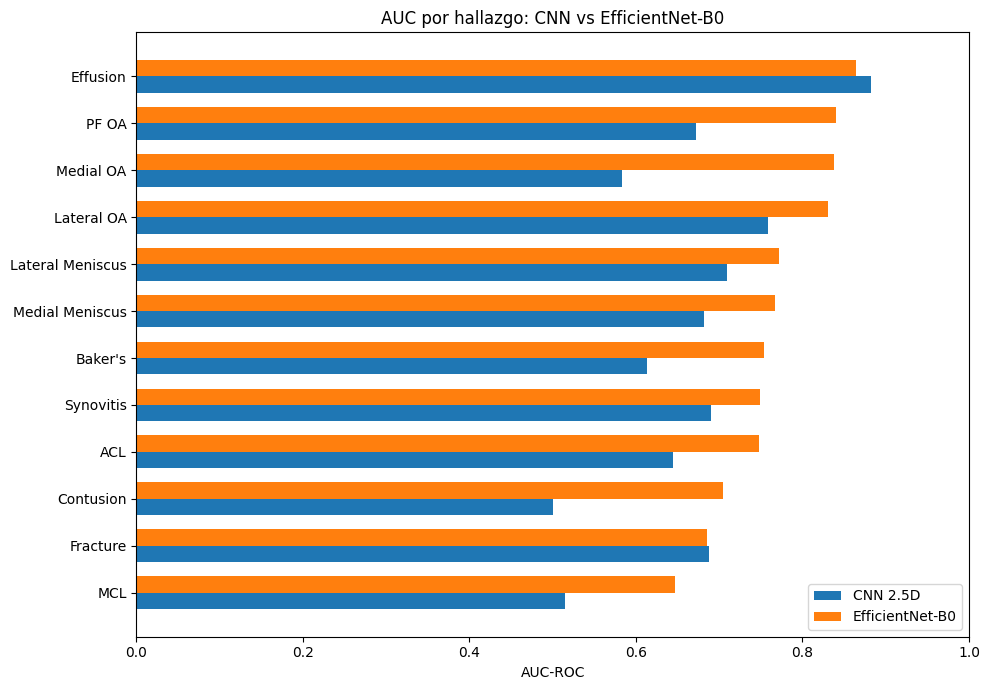

In [58]:
comparacion_plot = (
    comparacion_labels
    .sort_values("AUC_EfficientNet")
)

y = np.arange(
    len(comparacion_plot)
)

altura = 0.35

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    y - altura / 2,
    comparacion_plot["AUC_CNN"],
    height=altura,
    label="CNN 2.5D"
)

plt.barh(
    y + altura / 2,
    comparacion_plot["AUC_EfficientNet"],
    height=altura,
    label="EfficientNet-B0"
)

plt.yticks(
    y,
    comparacion_plot["Label"]
)

plt.xlabel(
    "AUC-ROC"
)

plt.title(
    "AUC por hallazgo: CNN vs EfficientNet-B0"
)

plt.xlim(
    0,
    1
)

plt.legend()

plt.tight_layout()
plt.show()

In [59]:
resumen_modelos.to_csv(
    "/kaggle/working/"
    "comparacion_modelos_macro.csv",
    index=False
)

comparacion_labels.to_csv(
    "/kaggle/working/"
    "comparacion_auc_por_label.csv",
    index=False
)

print(
    "Comparación guardada correctamente."
)

Comparación guardada correctamente.


## 18. Conclusiones de la comparación

EfficientNet-B0 obtuvo el mejor desempeño global sobre el conjunto GOLD DEV, alcanzando un
AUC-ROC macro de 0.7665 frente a 0.6614 de la CNN 2.5D entrenada desde cero.

Esto representa una mejora absoluta de aproximadamente 0.105 en AUC macro. El modelo
preentrenado también obtuvo mayor precisión y F1 macro, aunque la CNN desde cero alcanzó
un recall superior.

EfficientNet-B0 mejoró el AUC en 10 de los 12 hallazgos evaluados, con las mayores ganancias
en osteoartrosis medial, contusión y osteoartrosis patelofemoral. En Effusion y Fracture la CNN
obtuvo resultados ligeramente superiores.

Estos resultados sugieren que el conocimiento transferido desde ImageNet proporciona
representaciones visuales útiles incluso ante el cambio de dominio hacia imágenes MRI,
aunque el tamaño reducido del conjunto GOLD DEV obliga a interpretar las diferencias con
precaución.